# MNIST interval bound propagation

This notebook trains two copies of a fully connected $784 \to 50 \to 50 \to 50 \to 10$ network on the 60,000 training images and evaluates them on all 10,000 test images. Each hidden layer uses ReLU. The final layer returns logits for cross-entropy. All perturbation radii are in the original $[0,1]$ pixel scale, with the HW2 normalization applied inside the model.

In [1]:
import copy
import gzip
import hashlib
import struct
import time
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
BATCH_SIZE = 256
EPOCHS = 24
WARMUP_EPOCHS = 3
RAMP_EPOCHS = 12
EPS_TRAIN = 0.10
KAPPA_FINAL = 0.50
LEARNING_RATE = 1e-3
LR_MILESTONES = [18, 22]
PGD_STEPS = 40
PGD_RESTARTS = 5
RADII = [i / 100 for i in range(1, 11)]

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(2, torch.get_num_threads()))
device_name = (
    torch.cuda.get_device_name(device) if device.type == "cuda"
    else f"CPU, {torch.get_num_threads()} PyTorch threads"
)
print(f"PyTorch {torch.__version__} | {device_name} | seed {SEED}")

PyTorch 2.14.1+cu130 | Tesla T4 | seed 42


In [2]:
MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "440fcabf73cc546fa21475e81ea370265605f56be210a4024d2ca8f203523609",
    "train-labels-idx1-ubyte.gz": "3552534a0a558bbed6aed32b30c495cca23d567ec52cac8be1a0730e8010255c",
    "t10k-images-idx3-ubyte.gz": "8d422c7b0a1c1c79245a5bcf07fe86e33eeafee792b84584aec276f5a2dbc4e6",
    "t10k-labels-idx1-ubyte.gz": "f7ae60f92e00ec6debd23a6088c31dbd2371eca3ffa0defaefb259924204aec6",
}
MNIST_MIRRORS = [
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
    "https://storage.googleapis.com/cvdf-datasets/mnist/",
]


def load_mnist_file(filename, root=Path("mnist_data")):
    root.mkdir(exist_ok=True)
    path = root / filename
    expected = MNIST_FILES[filename]
    if path.is_file():
        compressed = path.read_bytes()
        if hashlib.sha256(compressed).hexdigest() == expected:
            return gzip.decompress(compressed)

    for mirror in MNIST_MIRRORS:
        try:
            with urlopen(mirror + filename, timeout=30) as response:
                compressed = response.read()
        except (URLError, TimeoutError):
            continue
        if hashlib.sha256(compressed).hexdigest() == expected:
            path.write_bytes(compressed)
            return gzip.decompress(compressed)
    raise RuntimeError(f"Could not download a valid MNIST file: {filename}")


def load_mnist(split):
    image_bytes = load_mnist_file(f"{split}-images-idx3-ubyte.gz")
    label_bytes = load_mnist_file(f"{split}-labels-idx1-ubyte.gz")
    magic, count, height, width = struct.unpack_from(">4I", image_bytes)
    label_magic, label_count = struct.unpack_from(">2I", label_bytes)
    assert (magic, label_magic, label_count, height, width) == (2051, 2049, count, 28, 28)
    pixels = np.frombuffer(image_bytes, dtype=np.uint8, offset=16).reshape(count, 784)
    labels = np.frombuffer(label_bytes, dtype=np.uint8, offset=8)
    images = torch.from_numpy(pixels.astype(np.float32)).div_(255)
    return TensorDataset(images, torch.from_numpy(labels.astype(np.int64)))


train_data = load_mnist("train")
test_data = load_mnist("t10k")
assert (len(train_data), len(test_data)) == (60_000, 10_000)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
print(f"{len(train_data):,} training images and {len(test_data):,} test images")

60,000 training images and 10,000 test images


## Part (a) · IBP training


In [3]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.ModuleList([nn.Linear(784, 50), nn.Linear(50, 50), nn.Linear(50, 50)])
        self.classifier = nn.Linear(50, 10)

    @staticmethod
    def normalize(x):
        return (x - 0.1307) / 0.3081

    def forward(self, x):
        x = self.normalize(x.flatten(start_dim=1))
        for layer in self.hidden:
            x = F.relu(layer(x))
        return self.classifier(x)


def pixel_box(images, epsilon):
    return (images - epsilon).clamp(min=0.0), (images + epsilon).clamp(max=1.0)


def box_center_radius(lower, upper):
    return (lower + upper) * 0.5, (upper - lower) * 0.5


def affine_box(layer, lower, upper):
    center, radius = box_center_radius(lower, upper)
    mapped_center = layer(center)
    mapped_radius = F.linear(radius, layer.weight.abs())
    return mapped_center - mapped_radius, mapped_center + mapped_radius


def hidden_box(model, images, epsilon):
    lower, upper = pixel_box(images.flatten(start_dim=1), epsilon)
    lower, upper = model.normalize(lower), model.normalize(upper)
    for layer in model.hidden:
        lower, upper = affine_box(layer, lower, upper)
        lower, upper = F.relu(lower), F.relu(upper)
    return lower, upper


def merged_upper_margins(model, images, labels, epsilon):
    center, radius = box_center_radius(*hidden_box(model, images, epsilon))
    weight, bias = model.classifier.weight, model.classifier.bias
    weight_diff = weight[None, :, :] - weight[labels, None, :]
    bias_diff = bias[None, :] - bias[labels, None]
    center_margins = torch.bmm(weight_diff, center.unsqueeze(-1)).squeeze(-1) + bias_diff
    radius_margins = torch.bmm(weight_diff.abs(), radius.unsqueeze(-1)).squeeze(-1)
    return center_margins + radius_margins

In [4]:
def schedule(epoch, batch, num_batches):
    ramp_steps = RAMP_EPOCHS * num_batches
    step_into_ramp = (epoch - WARMUP_EPOCHS) * num_batches + batch
    progress = min(1.0, max(0.0, step_into_ramp / (ramp_steps - 1)))
    return EPS_TRAIN * progress, 1.0 - (1.0 - KAPPA_FINAL) * progress


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def train_model(model, use_ibp):
    model.train()
    loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=LR_MILESTONES, gamma=0.35)
    history = []
    name = "IBP" if use_ibp else "Standard"
    synchronize()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        epoch_loss = torch.zeros((), device=device)
        for batch, (images, labels) in enumerate(loader):
            images, labels = images.to(device), labels.to(device)
            epsilon, kappa = schedule(epoch, batch, len(loader)) if use_ibp else (0.0, 1.0)
            optimizer.zero_grad(set_to_none=True)
            clean_loss = F.cross_entropy(model(images), labels)
            loss = clean_loss
            if kappa < 1.0:
                robust_logits = merged_upper_margins(model, images, labels, epsilon)
                robust_loss = F.cross_entropy(robust_logits, labels)
                loss = kappa * clean_loss + (1.0 - kappa) * robust_loss
            loss.backward()
            optimizer.step()
            epoch_loss += loss.detach() * labels.size(0)
        scheduler.step()
        average_loss = epoch_loss.item() / len(train_data)
        history.append((average_loss, epsilon, kappa))
        if epoch + 1 in {1, WARMUP_EPOCHS, WARMUP_EPOCHS + RAMP_EPOCHS, EPOCHS}:
            print(
                f"{name:8s} | epoch {epoch + 1:2d}/{EPOCHS} | loss {average_loss:.4f} "
                f"| epsilon {epsilon:.3f} | kappa {kappa:.3f}"
            )
    synchronize()
    return history, time.perf_counter() - start


torch.manual_seed(SEED)
initial_model = MNISTMLP()
standard_model = copy.deepcopy(initial_model).to(device)
ibp_model = copy.deepcopy(initial_model).to(device)
standard_history, standard_seconds = train_model(standard_model, use_ibp=False)
ibp_history, ibp_seconds = train_model(ibp_model, use_ibp=True)
print(f"Standard training {standard_seconds:.2f} s | IBP training {ibp_seconds:.2f} s")

Standard | epoch  1/24 | loss 0.5406 | epsilon 0.000 | kappa 1.000
Standard | epoch  3/24 | loss 0.1553 | epsilon 0.000 | kappa 1.000
Standard | epoch 15/24 | loss 0.0363 | epsilon 0.000 | kappa 1.000
Standard | epoch 24/24 | loss 0.0080 | epsilon 0.000 | kappa 1.000
IBP      | epoch  1/24 | loss 0.5406 | epsilon 0.000 | kappa 1.000
IBP      | epoch  3/24 | loss 0.1553 | epsilon 0.000 | kappa 1.000
IBP      | epoch 15/24 | loss 0.6071 | epsilon 0.100 | kappa 0.500
IBP      | epoch 24/24 | loss 0.5082 | epsilon 0.100 | kappa 0.500
Standard training 21.59 s | IBP training 44.45 s


### Clean and PGD accuracy


In [5]:
@torch.no_grad()
def clean_predictions(model):
    model.eval()
    return torch.cat([model(images.to(device)).argmax(1).cpu() for images, _ in test_loader])


def pgd_linf(model, images, labels, epsilon, rng):
    lower, upper = pixel_box(images, epsilon)
    found = torch.zeros_like(labels, dtype=torch.bool)
    witnesses = images.clone()
    alpha = epsilon / 10

    for _ in range(PGD_RESTARTS):
        active = torch.where(~found)[0]
        if active.numel() == 0:
            break
        lo, hi, y = lower[active], upper[active], labels[active]
        candidate = lo + (hi - lo) * torch.rand(lo.shape, device=lo.device, generator=rng)
        restart_found = torch.zeros_like(y, dtype=torch.bool)
        restart_witnesses = witnesses[active]

        for step in range(PGD_STEPS + 1):
            candidate = candidate.detach().requires_grad_()
            logits = model(candidate)
            with torch.no_grad():
                wrong = logits.argmax(1).ne(y)
                first_wrong = wrong & ~restart_found
                restart_witnesses[first_wrong] = candidate[first_wrong]
                restart_found |= wrong
            if step == PGD_STEPS or restart_found.all():
                break
            loss = F.cross_entropy(logits, y, reduction="sum")
            gradient, = torch.autograd.grad(loss, candidate)
            with torch.no_grad():
                candidate = (candidate + alpha * gradient.sign()).clamp(min=lo, max=hi)

        found[active] = restart_found
        witnesses[active] = restart_witnesses

    return found, witnesses


def attack_test_set(model, epsilon, eligible, example_limit=0):
    model.eval()
    images, labels = test_data.tensors
    rng = torch.Generator(device=device).manual_seed(SEED + round(100 * epsilon))
    flipped = torch.zeros(len(test_data), dtype=torch.bool)
    examples = []
    for indices in torch.where(eligible)[0].split(BATCH_SIZE):
        if indices.numel() == 0:
            continue
        x, y = images[indices].to(device), labels[indices].to(device)
        found, adversarial = pgd_linf(model, x, y, epsilon, rng)
        flipped[indices] = found.cpu()
        with torch.no_grad():
            adversarial = adversarial[found]
            clean = x[found]
            truth = y[found]
            if truth.numel() == 0:
                continue
            predictions = model(adversarial).argmax(1)
            assert (predictions != truth).all()
            assert ((adversarial >= 0) & (adversarial <= 1)).all()
            assert ((adversarial - clean).abs().amax(1) <= epsilon + 1e-6).all()

            take = max(0, min(example_limit - len(examples), truth.numel()))
            records = zip(
                indices[found.cpu()][:take].tolist(),
                clean[:take].cpu(),
                adversarial[:take].cpu(),
                truth[:take].tolist(),
                predictions[:take].tolist(),
            )
            examples.extend(records)
    return flipped, examples


def markdown_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


def percent(mask):
    return 100 * mask.sum().item() / len(test_data)

In [9]:
test_labels = test_data.tensors[1]
standard_correct = clean_predictions(standard_model).eq(test_labels)
ibp_correct = clean_predictions(ibp_model).eq(test_labels)

standard_flipped, _ = attack_test_set(standard_model, EPS_TRAIN, standard_correct)
ibp_flipped, ibp_examples = attack_test_set(ibp_model, EPS_TRAIN, ibp_correct, example_limit=12)
standard_pgd = percent(standard_correct & ~standard_flipped)
ibp_pgd = percent(ibp_correct & ~ibp_flipped)

markdown_table(
    ["Training method", "Clean accuracy", "PGD accuracy at ε = 0.10", "Training time"],
    [
        ["Standard", f"{percent(standard_correct):.2f}%", f"{standard_pgd:.2f}%", f"{standard_seconds:.2f} s"],
        ["IBP", f"{percent(ibp_correct):.2f}%", f"{ibp_pgd:.2f}%", f"{ibp_seconds:.2f} s"],
    ],
)
clean_change = percent(ibp_correct) - percent(standard_correct)
pgd_change = ibp_pgd - standard_pgd
print("speed:"+ str(ibp_seconds / standard_seconds) +"   clean accuracy: "+ str(clean_change) + "   PGD chnage:"+ str(pgd_change))

| Training method | Clean accuracy | PGD accuracy at ε = 0.10 | Training time |
| --- | --- | --- | --- |
| Standard | 97.61% | 3.90% | 21.59 s |
| IBP | 94.37% | 83.08% | 44.45 s |

speed:2.0592665569230006   clean accuracy: -3.239999999999995   PGD chnage:79.17999999999999


## Part (b) · HW2-style box verification

In [10]:
@torch.no_grad()
def box_verifier(model, images, labels, epsilon):
    lower, upper = affine_box(model.classifier, *hidden_box(model, images, epsilon))
    true_lower = lower.gather(1, labels[:, None]).squeeze(1)
    rival_upper = upper.scatter(1, labels[:, None], -torch.inf).amax(1)
    return true_lower - rival_upper > 1e-8


verifier_model = copy.deepcopy(ibp_model).double().eval()


@torch.no_grad()
def certify_test_set(epsilon):
    return torch.cat([
        box_verifier(verifier_model, images.to(device, dtype=torch.float64), labels.to(device), epsilon).cpu()
        for images, labels in test_loader
    ])

sample_x, sample_y = next(iter(test_loader))
sample_x = sample_x[:16].to(device, dtype=torch.float64)
sample_y = sample_y[:16].to(device)
with torch.no_grad():
    nominal = verifier_model(sample_x)
    lower, upper = affine_box(verifier_model.classifier, *hidden_box(verifier_model, sample_x, 0))
    torch.testing.assert_close(lower, nominal)
    torch.testing.assert_close(upper, nominal)
    torch.testing.assert_close(
        merged_upper_margins(verifier_model, sample_x, sample_y, 0),
        nominal - nominal.gather(1, sample_y[:, None]),
    )
    lower, upper = affine_box(verifier_model.classifier, *hidden_box(verifier_model, sample_x, EPS_TRAIN))
    merged = merged_upper_margins(verifier_model, sample_x, sample_y, EPS_TRAIN)
    direct = upper - lower.gather(1, sample_y[:, None])
    assert (merged <= direct + 1e-8).all()

| ε | Certified | Verified accuracy | PGD flips | Clean errors | Unresolved | PGD accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| 0.01 | 9,297 | 92.97% | 72 | 563 | 68 | 93.65% |
| 0.02 | 9,132 | 91.32% | 141 | 563 | 164 | 92.96% |
| 0.03 | 8,920 | 89.20% | 223 | 563 | 294 | 92.14% |
| 0.04 | 8,686 | 86.86% | 292 | 563 | 459 | 91.45% |
| 0.05 | 8,359 | 83.59% | 400 | 563 | 678 | 90.37% |
| 0.06 | 8,002 | 80.02% | 511 | 563 | 924 | 89.26% |
| 0.07 | 7,566 | 75.66% | 639 | 563 | 1,232 | 87.98% |
| 0.08 | 7,134 | 71.34% | 791 | 563 | 1,512 | 86.46% |
| 0.09 | 6,618 | 66.18% | 956 | 563 | 1,863 | 84.81% |
| 0.10 | 5,985 | 59.85% | 1,129 | 563 | 2,323 | 83.08% |

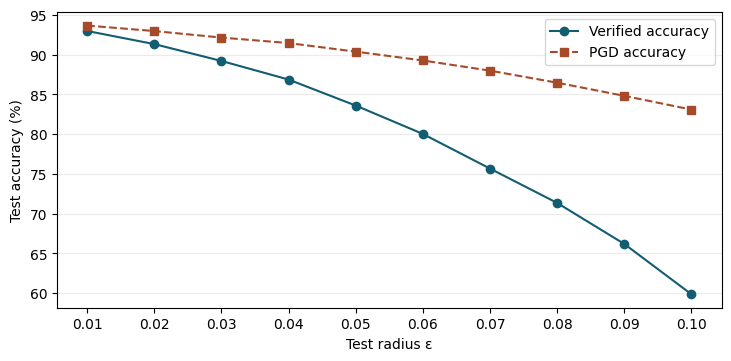

In [11]:
verification = []
examples_by_radius = {}
previous_certified = torch.ones_like(ibp_correct)

for epsilon in RADII:
    certified = certify_test_set(epsilon)
    assert not (certified & ~ibp_correct).any()
    assert not (certified & ~previous_certified).any()
    previous_certified = certified

    if epsilon == EPS_TRAIN:
        flipped, examples = ibp_flipped, ibp_examples
    else:
        eligible = ibp_correct & ~certified
        flipped, examples = attack_test_set(ibp_model, epsilon, eligible, example_limit=12)
    assert not (certified & flipped).any()
    unresolved = ibp_correct & ~certified & ~flipped
    verification.append((
        epsilon, certified.sum().item(), percent(certified), flipped.sum().item(),
        unresolved.sum().item(), percent(ibp_correct & ~flipped),
    ))
    examples_by_radius[epsilon] = examples

clean_errors = (~ibp_correct).sum().item()
assert all(cert + flips + unknown + clean_errors == len(test_data)
           for _, cert, _, flips, unknown, _ in verification)
markdown_table(
    ["ε", "Certified", "Verified accuracy", "PGD flips", "Clean errors", "Unresolved", "PGD accuracy"],
    [
        [f"{eps:.2f}", f"{cert:,}", f"{verified:.2f}%", f"{flips:,}", f"{clean_errors:,}",
         f"{unknown:,}", f"{empirical:.2f}%"]
        for eps, cert, verified, flips, unknown, empirical in verification
    ],
)

from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")
radii, _, verified_curve, _, _, pgd_curve = zip(*verification)
fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
ax.plot(radii, verified_curve, "o-", color="#125D72", label="Verified accuracy")
ax.plot(radii, pgd_curve, "s--", color="#A64B2A", label="PGD accuracy")
ax.set(xlabel="Test radius ε", ylabel="Test accuracy (%)", xticks=radii)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

### Adversarial examples

Verification results
Radius  Certified  Verified accuracy  PGD flips  Unresolved  PGD accuracy
0.01    9,297      92.97%             72         68          93.65%      
0.02    9,132      91.32%             141        164         92.96%      
0.03    8,920      89.20%             223        294         92.14%      
0.04    8,686      86.86%             292        459         91.45%      
0.05    8,359      83.59%             400        678         90.37%      
0.06    8,002      80.02%             511        924         89.26%      
0.07    7,566      75.66%             639        1,232       87.98%      
0.08    7,134      71.34%             791        1,512       86.46%      
0.09    6,618      66.18%             956        1,863       84.81%      
0.10    5,985      59.85%             1,129      2,323       83.08%      


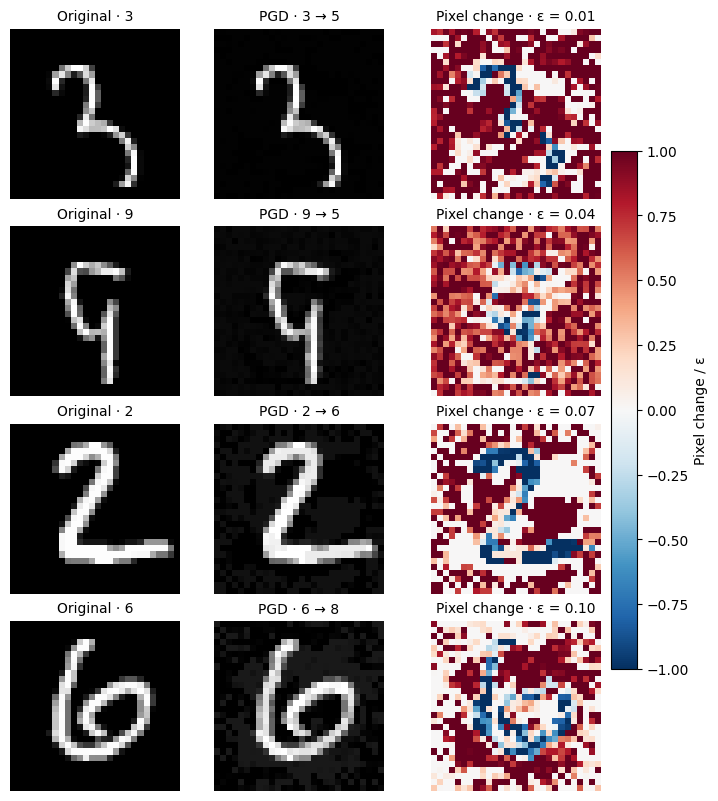


Adversarial examples
Test index  Radius  Verified accuracy  Clean → PGD  Max abs. change  Mean abs. change  Clean margin  PGD margin
195         0.01    92.97%             3 → 5        0.0100           0.0069            +0.186        -0.018    
62          0.04    86.86%             9 → 5        0.0400           0.0265            +0.893        -0.079    
1           0.07    75.66%             2 → 6        0.0700           0.0369            +3.169        -0.015    
11          0.10    59.85%             6 → 8        0.1000           0.0494            +2.795        -0.087    


In [12]:
def print_table(headers, rows):
    rows = [tuple(str(value) for value in row) for row in rows]
    widths = [max(map(len, column)) for column in zip(headers, *rows)]

    for row in [headers, *rows]:
        print("  ".join(value.ljust(width) for value, width in zip(row, widths)))


verified_by_radius = {eps: verified for eps, _, verified, _, _, _ in verification}

print("Verification results")
print_table(
    ["Radius", "Certified", "Verified accuracy", "PGD flips", "Unresolved", "PGD accuracy"],
    [
        (f"{eps:.2f}", f"{certified:,}", f"{verified:.2f}%", f"{flips:,}",
         f"{unresolved:,}", f"{pgd:.2f}%")
        for eps, certified, verified, flips, unresolved, pgd in verification
    ],
)

available_radii = [eps for eps in RADII if examples_by_radius[eps]]
selected = []
used_labels = set()

if available_radii:
    shown = np.linspace(0, len(available_radii) - 1, min(4, len(available_radii)), dtype=int)
    for index in shown:
        eps = available_radii[index]
        candidates = examples_by_radius[eps]
        example = next((item for item in candidates if item[3] not in used_labels), candidates[0])
        selected.append((eps, *example))
        used_labels.add(example[3])


@torch.no_grad()
def true_margin(model, image, label):
    logits = model(image.to(device).unsqueeze(0)).squeeze(0)
    rivals = logits.clone()
    rivals[label] = -torch.inf
    return (logits[label] - rivals.max()).item()


if selected:
    fig, axes = plt.subplots(
        len(selected), 3, figsize=(7.2, 1.85 * len(selected) + 0.5),
        squeeze=False, layout="constrained",
    )
    example_rows = []

    for row, (eps, index, original, adversarial, label, predicted) in enumerate(selected):
        delta = adversarial - original
        axes[row, 0].imshow(original.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        axes[row, 1].imshow(adversarial.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        heatmap = axes[row, 2].imshow(
            delta.reshape(28, 28) / eps, cmap="RdBu_r", vmin=-1, vmax=1,
        )

        axes[row, 0].set_title(f"Original · {label}", fontsize=10)
        axes[row, 1].set_title(f"PGD · {label} → {predicted}", fontsize=10)
        axes[row, 2].set_title(f"Pixel change · ε = {eps:.2f}", fontsize=10)
        for axis in axes[row]:
            axis.axis("off")

        example_rows.append((
            index,
            f"{eps:.2f}",
            f"{verified_by_radius[eps]:.2f}%",
            f"{label} → {predicted}",
            f"{delta.abs().max().item():.4f}",
            f"{delta.abs().mean().item():.4f}",
            f"{true_margin(ibp_model, original, label):+.3f}",
            f"{true_margin(ibp_model, adversarial, label):+.3f}",
        ))

    fig.colorbar(heatmap, ax=axes[:, 2], shrink=0.68, label="Pixel change / ε")
    plt.show()

    print("\nAdversarial examples")
    print_table(
        ["Test index", "Radius", "Verified accuracy", "Clean → PGD",
         "Max abs. change", "Mean abs. change", "Clean margin", "PGD margin"],
        example_rows,
    )